<a href="https://colab.research.google.com/github/Vikas7350/Debug_Thugs/blob/main/Dry_Bean_Classification_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical Assignment 4: Classification Models
## Dry Bean Variety Classification

**Aim:** To implement and compare Support Vector Machine (SVM), Decision Tree, K-Nearest Neighbors (KNN), and Gaussian Naive Bayes classifiers using the Dry Bean dataset.

**Dataset source:** UCI Machine Learning Repository — Dry Bean Dataset  
https://archive.ics.uci.edu/dataset/602/dry+bean

**Target:** `Class` (seven bean varieties).  
**Evaluation:** Accuracy, weighted precision, weighted recall, weighted F1-score, log loss, classification reports, and confusion matrices.

> Run each cell from top to bottom. The notebook downloads the dataset through `ucimlrepo`, so use an internet-enabled Jupyter or Google Colab session. The reported metrics will be generated by your own run.


In [14]:
%pip install -q ucimlrepo

In [15]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


## 1. Import libraries

## 2. Load and inspect the dataset

In [16]:
# Fetch the Dry Bean dataset from the UCI Machine Learning Repository
dry_bean = fetch_ucirepo(id=602)
X = dry_bean.data.features.copy()
y = dry_bean.data.targets.iloc[:, 0].copy()

df = X.copy()
df["Class"] = y

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())
print("\nDataset information:")
display(df.describe().T)
print("\nMissing values per column:")
display(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
display(df["Class"].value_counts().sort_index())


Dataset shape: (13611, 17)

First five rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Dataset information:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677



Missing values per column:


,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0



Duplicate rows: 68

Class distribution:


,count
Class,
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1928
SEKER,2027
SIRA,2636


## 3. Explore the target classes

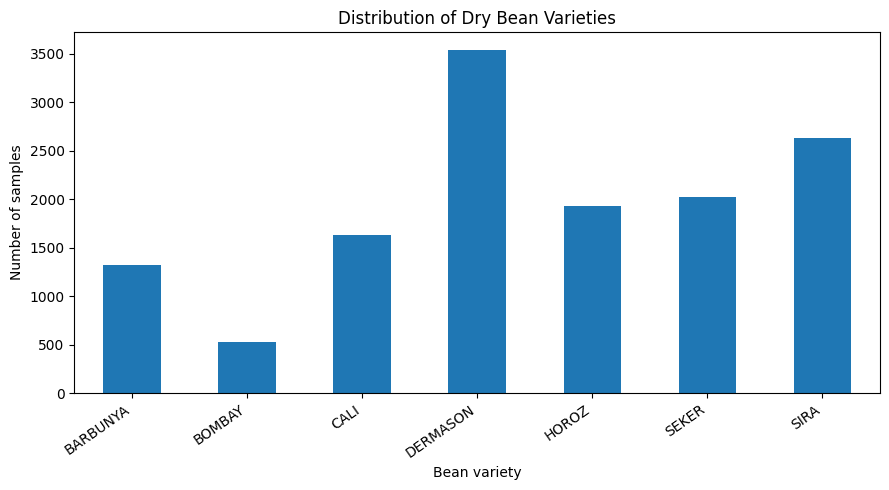

Number of observations: 13611
Number of input features: 16
Number of classes: 7
Class labels: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [17]:
class_counts = df["Class"].value_counts().sort_index()
ax = class_counts.plot(kind="bar", figsize=(9, 5))
ax.set_title("Distribution of Dry Bean Varieties")
ax.set_xlabel("Bean variety")
ax.set_ylabel("Number of samples")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Number of observations:", len(df))
print("Number of input features:", X.shape[1])
print("Number of classes:", y.nunique())
print("Class labels:", sorted(y.unique()))


## 4. Prepare training and testing data

In [18]:
# Remove duplicate rows if any; this keeps the target aligned with the features.
combined = df.drop_duplicates().reset_index(drop=True)
X = combined.drop(columns="Class")
y = combined["Class"]

# Stratified 75:25 split ensures each class is represented proportionally.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3))


Training samples: 10157
Testing samples: 3386

Training class proportions:


,proportion
Class,
BARBUNYA,0.098
BOMBAY,0.039
CALI,0.120
DERMASON,0.262
HOROZ,0.137
SEKER,0.150
SIRA,0.195


## 5. Define classification models

In [19]:
models = {
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN (k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

print("Models prepared:", ", ".join(models.keys()))


Models prepared: SVM (RBF), Decision Tree, KNN (k=5), Gaussian Naive Bayes


## 6. Train, predict, and evaluate the models

In [20]:
results = []
confusion_matrices = {}
classification_reports = {}
class_order = sorted(y.unique())

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-Score (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "Log Loss": log_loss(y_test, probabilities, labels=model.classes_)
    })

    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=class_order)
    classification_reports[name] = classification_report(
        y_test, predictions, zero_division=0
    )

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (weighted)": "{:.4f}",
    "Recall (weighted)": "{:.4f}",
    "F1-Score (weighted)": "{:.4f}",
    "Log Loss": "{:.4f}"
}))


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-Score (weighted),Log Loss
0,SVM (RBF),0.9232,0.9238,0.9232,0.9233,0.2084
1,KNN (k=5),0.9158,0.9165,0.9158,0.9160,1.0315
2,Gaussian Naive Bayes,0.8984,0.9009,0.8984,0.8986,0.9789
3,Decision Tree,0.8949,0.8947,0.8949,0.8947,3.7896


## 7. Classification reports

In [21]:
for name, report in classification_reports.items():
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(report)



SVM (RBF)
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.90      0.92       330
      BOMBAY       1.00      1.00      1.00       130
        CALI       0.94      0.95      0.95       408
    DERMASON       0.92      0.91      0.91       887
       HOROZ       0.97      0.95      0.96       465
       SEKER       0.94      0.95      0.94       507
        SIRA       0.86      0.88      0.87       659

    accuracy                           0.92      3386
   macro avg       0.94      0.93      0.94      3386
weighted avg       0.92      0.92      0.92      3386


Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.89      0.88      0.89       330
      BOMBAY       1.00      1.00      1.00       130
        CALI       0.91      0.92      0.91       408
    DERMASON       0.88      0.89      0.89       887
       HOROZ       0.95      0.93      0.94       465
       SEKER       0.92      0.93      0.93       50

## 8. Confusion matrices

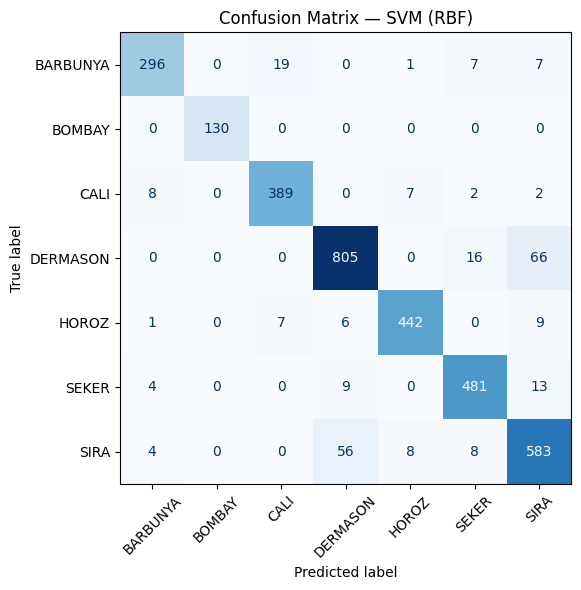

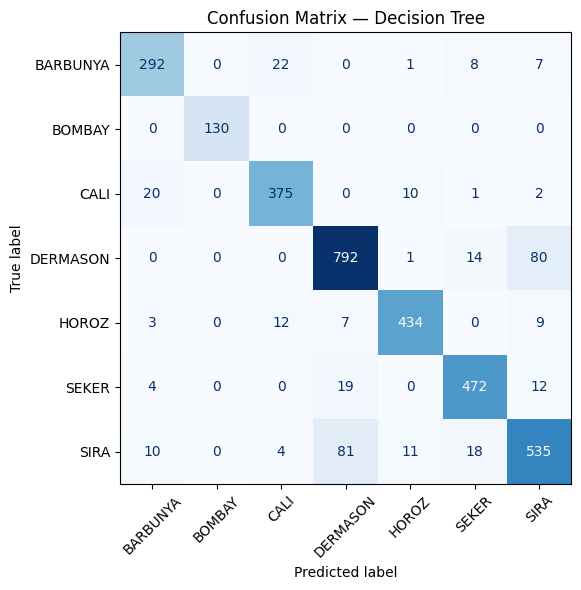

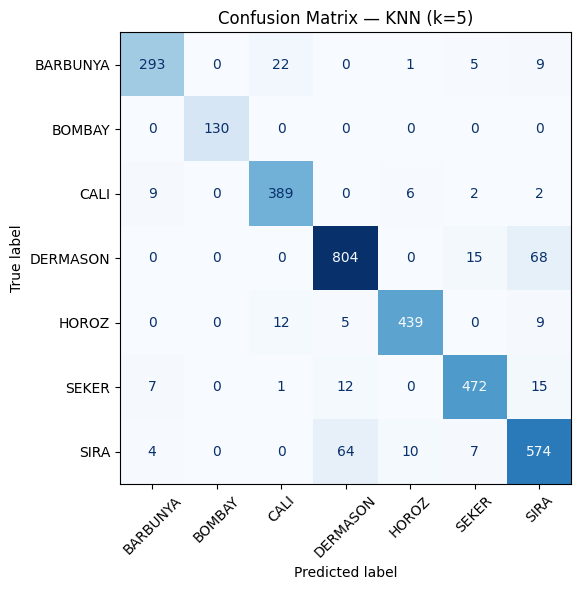

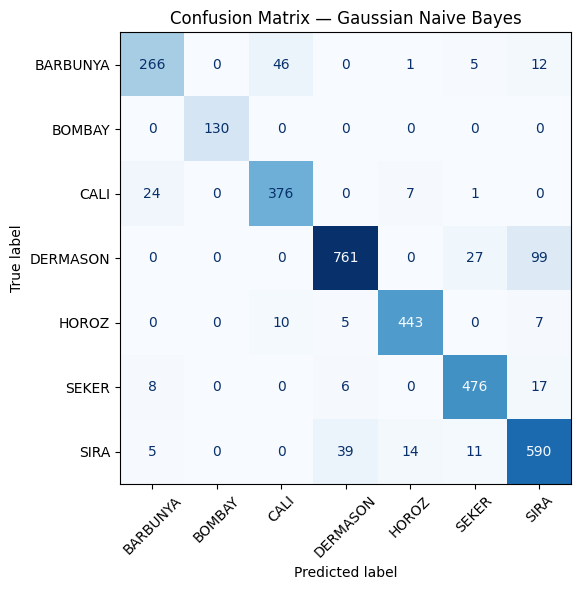

In [22]:
for name, matrix in confusion_matrices.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_order)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


## 9. Compare model performance

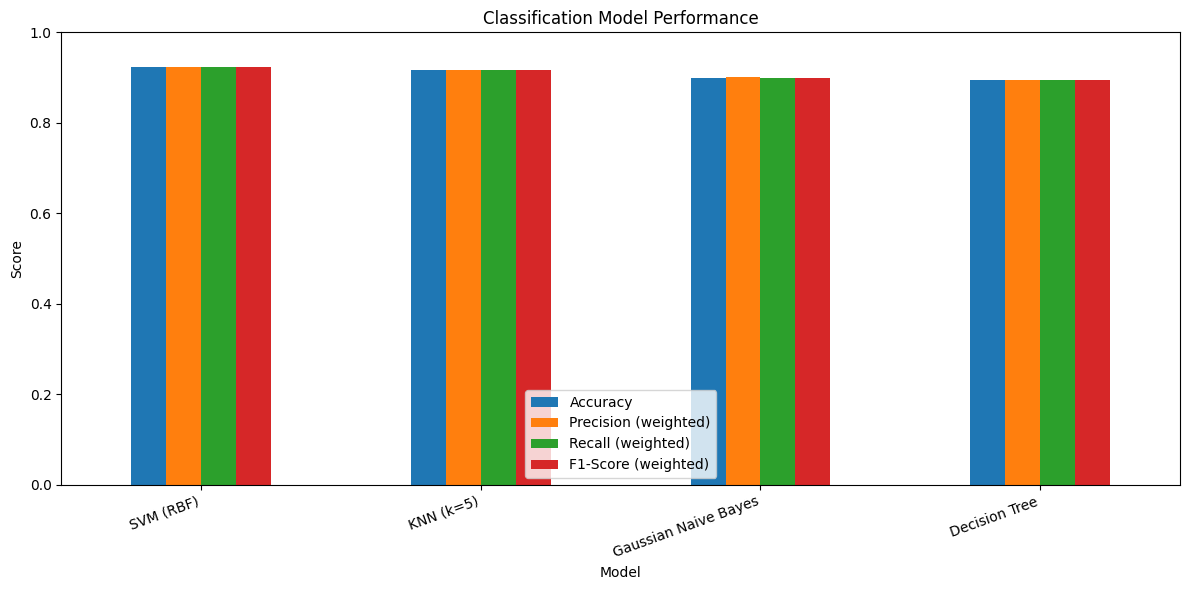

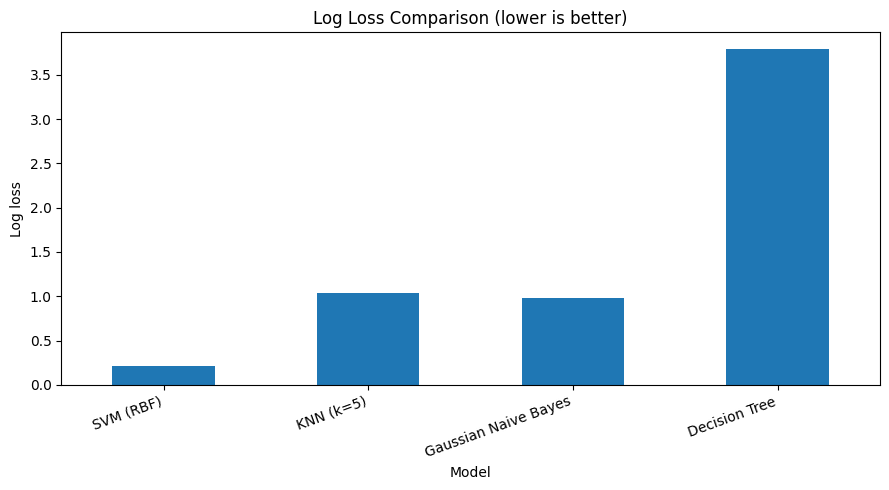

In [23]:
metric_columns = [
    "Accuracy", "Precision (weighted)", "Recall (weighted)",
    "F1-Score (weighted)", "Log Loss"
]
plot_df = results_df.set_index("Model")[metric_columns]

ax = plot_df[["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-Score (weighted)"]].plot(
    kind="bar", figsize=(12, 6)
)
ax.set_title("Classification Model Performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

ax = results_df.set_index("Model")["Log Loss"].plot(kind="bar", figsize=(9, 5))
ax.set_title("Log Loss Comparison (lower is better)")
ax.set_ylabel("Log loss")
ax.set_xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## 10. Identify the best-performing models

In [24]:
best_accuracy = results_df.loc[results_df["Accuracy"].idxmax()]
best_f1 = results_df.loc[results_df["F1-Score (weighted)"].idxmax()]
best_logloss = results_df.loc[results_df["Log Loss"].idxmin()]

print(f"Highest accuracy: {best_accuracy['Model']} ({best_accuracy['Accuracy']:.4f})")
print(f"Highest weighted F1-score: {best_f1['Model']} ({best_f1['F1-Score (weighted)']:.4f})")
print(f"Lowest log loss: {best_logloss['Model']} ({best_logloss['Log Loss']:.4f})")

# Export the real results from this run for use in the written report.
results_df.to_csv("dry_bean_model_comparison.csv", index=False)
print("\nSaved model comparison to dry_bean_model_comparison.csv")


Highest accuracy: SVM (RBF) (0.9232)
Highest weighted F1-score: SVM (RBF) (0.9233)
Lowest log loss: SVM (RBF) (0.2084)

Saved model comparison to dry_bean_model_comparison.csv


## 11. Conclusion

This practical compares four supervised classification algorithms—SVM, Decision Tree, KNN, and Gaussian Naive Bayes—on the UCI Dry Bean dataset. The input features describe bean geometry and shape, while the target is the bean variety.

The models are evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, log loss, and confusion matrices. Use the values printed in Sections 6 and 10 to complete the written conclusion. The model with the highest accuracy is best for overall correct class predictions in this split, while lower log loss indicates better predicted probability quality. Results depend on the split, preprocessing, and model settings.

## References
1. UCI Machine Learning Repository. *Dry Bean*. https://archive.ics.uci.edu/dataset/602/dry+bean
2. Scikit-learn Developers. *SVC*. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
3. Scikit-learn Developers. *DecisionTreeClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
4. Scikit-learn Developers. *KNeighborsClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
5. Scikit-learn Developers. *GaussianNB*. https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
6. Scikit-learn Developers. *Model evaluation*. https://scikit-learn.org/stable/modules/model_evaluation.html
